<a href="https://colab.research.google.com/github/R3ALITI3S/MachineLearningMiniProject/blob/Book/MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity recognition with healthy older people using a batteryless wearable sensor - ML Mini-Project
This is my submission for an Activity recognition classification, that aims to destinguish between four different physical activites of healthy older people using data collected from a batteryless wearable sensor. I will go through an exploration of the dataset, how the model was developed, which decicions i made regarding model selection and final evaluation and results.

The dataset contains measurements from 14 older people to classify four activities. One important characteristic is that the dataset is unbalanced as some activities have significantly more observations than others.

The possible class labels assigned for every sensor observation are:
1. Sitting on a bed: 3,296 observations
2. Sitting on a chair: 18,021 observations
3. Lying on a bed: 51,520 observations
4. Ambulating: 2,291 observations (where ambulating includes standing, walking around the room.)

The dataset: https://archive.ics.uci.edu/dataset/427/activity+recognition+with+healthy+older+people+using+a+batteryless+wearable+sensor

The placement of the electrode:

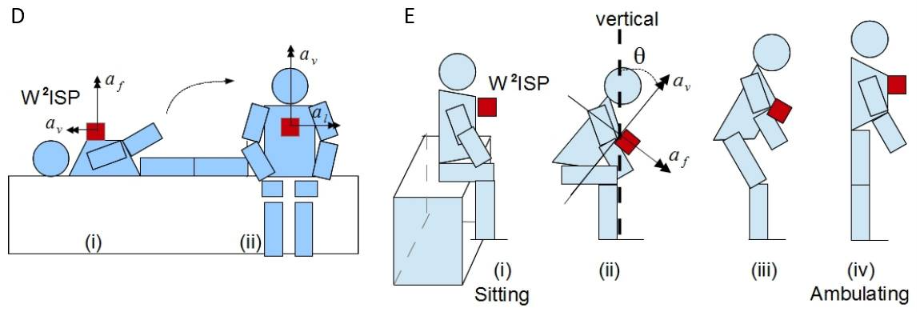

The image is taken from: _https://pmc.ncbi.nlm.nih.gov/articles/PMC4851060/_

Here is a visualization of the axies:

![image.png](attachment:5a81bc5d-0b07-43ba-8f3f-d1b8d75106f0.png)

Picture taken from: _https://lex.dk/sagittalplan_

# 0. Environment and imports
This cellblock below is for loading the relevant packages and imports. I imported `sklearn`, `numpy`, `pandas`, `matplotlib`, `pathlib` and `seaborn`.

`sklearn (Scikit-learn):` For ML, data preprocessing, model training, hyperparameter tuning, cross-validation and model evaluation

`numpy:` For numerical operations, working with arrays and mathematical calculations

`pandas:` Used for loading, organizing, cleaning and manipulating the dataset using DataFrames

`matplotlib:` To create visualizations, such as plots, histograms, and charts

`pathlib:` Handeling file paths, and making it easier to locate and load datasets

`Seaborn:` For statistical data visualizations, which helps identify distributions, patterns, correlations and relationships between and across features


In [202]:
# Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Paths
from pathlib import Path

from scipy.stats import logistic
# Data splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedShuffleSplit,
    cross_val_score
)

# Data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer,
    PolynomialFeatures
)

# Pipelines
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier

# Dimensionality reduction and feature selection
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectFromModel

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

# 1. Setup and data loading
The data is downloaded from: https://archive.ics.uci.edu/dataset/427/activity+recognition+with+healthy+older+people+using+a+batteryless+wearable+sensor.

The dataset consists of multiple individual files containing recordings from 14 participants, divided into two clinical room settings: `1_Dataset` and `S2_Dataset`. Room 1 uses four RFID antennas, while Room 2 uses three.

Each file contains 9 columns: 8 sensor measurements and 1 activity label. `pathlib` for locate the downloaded files, and pandas to read them individually. Then assign column names and add them to their specefic folders.

Then combine all training instances are fit into a `DataFrame` using `pd.concat()`. Then a `df.head()` to verify the data is loaded correctly.



In [60]:
np.random.seed(42)          # reproducible results (Ch. 2)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [61]:
# Import the dataset
base_folder = Path(r"C:\Users\nield\Desktop\GitHub\MachineLearningMiniProject\activity+recognition+with+healthy+older+people+using+a+batteryless+wearable+sensor")

# Columns
columns = ["time", "accel_frontal", "accel_vertical", "accel_lateral", "antenna_id", "RSSI", "phase", "frequency", "activity"]

# Open the dataset
dataframes = []

for folder_name in ["S1_Dataset", "S2_Dataset"]:
    for file in (base_folder / folder_name).iterdir():
        if file.is_file():
            try:
                temp_df = pd.read_csv(file, header=None, sep=None, engine="python")

                if temp_df.shape[1] == len(columns):
                    temp_df.columns = columns
                    temp_df["subject_folder"] = folder_name
                    temp_df["source_file"] = file.name
                    dataframes.append(temp_df)
            except Exception:
                pass

df = pd.concat(dataframes, ignore_index=True)

# Prints, can be removed later.
print("The shape of the dataset", df.shape)
df.head() # show the data in a table

The shape of the dataset (75128, 11)


,time,accel_frontal,accel_vertical,accel_lateral,antenna_id,RSSI,phase,frequency,activity,subject_folder,source_file
0,0.00,0.27203,1.00820,-0.082102,1,-63.5,2.4252,924.25,1,S1_Dataset,d1p01M
1,0.50,0.27203,1.00820,-0.082102,1,-63.0,4.7369,921.75,1,S1_Dataset,d1p01M
2,1.50,0.44791,0.91636,-0.013684,1,-63.5,3.0311,923.75,1,S1_Dataset,d1p01M
3,1.75,0.44791,0.91636,-0.013684,1,-63.0,2.0371,921.25,1,S1_Dataset,d1p01M
4,2.50,0.34238,0.96229,-0.059296,1,-63.5,5.8920,920.25,1,S1_Dataset,d1p01M


# 2. Split the data
- **Training set:** The model learns from it
- **Validation ("dev") set:** used to compare models and hyperparameters. (if used the training for it, tuning would be happening and the final score would bee too optimistic)
- **Test set:** touched only **once** at the end to estimate how the model works on new unseen data (generalization error)

`X` contains the 8 input features, while `y` is the class the model are expected to predict.

**Cross-validation instead of one fixed dev set:** guideline 3 asks us to use cross-validation on training+dev. Ch. 2 explains that K-fold CV splits the training+dev data into K folds and, in turn, uses each fold as the validation set. This gives a more reliable estimate than a single dev split and uses all the data. So we split once into **train (60%)**, **val (20%)** and **test (20%)**; the dev sets are the CV folds.

**Why `stratify=y`:** Ch. 2 introduces *stratified sampling*, so every split has the same class proportions as the full data and the test set is representative.


In [195]:
# Separate features (X) and target (y)
X = df.drop(columns=[
    "activity",
    "source_file",
    "time",
    "subject_folder"
])

y = df["activity"]

RANDOM_STATE = 42

# Split 1: 60% training, 40% remaining
X_train, X_remaining, y_train, y_remaining = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=y
)

# Split 2: 20% validation, 20% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_remaining
)

# Check dataset sizes
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

# Check class distributions
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name} class distribution (%):")
    print((labels.value_counts(normalize=True) * 100)
          .sort_index().round(2))

# Check that feature and target counts match
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("\nAll feature and target sets match!")

Training: (45076, 7) (45076,)
Validation: (15026, 7) (15026,)
Testing: (15026, 7) (15026,)

Training class distribution (%):
activity
1    21.84
2     6.54
3    68.58
4     3.05
Name: proportion, dtype: float64

Validation class distribution (%):
activity
1    21.84
2     6.54
3    68.58
4     3.05
Name: proportion, dtype: float64

Testing class distribution (%):
activity
1    21.84
2     6.54
3    68.57
4     3.05
Name: proportion, dtype: float64

All feature and target sets match!


`time` is dropped, as it tells os nothing about the person's posture. So if kept then it could let a model learn when in a recording things happen, whitch would not generalize to new recordings.

> **Honest limitation:** consecutive rows from the same recording are very similar. A random split puts neighbouring rows in both train and test, which tends to make scores look better than they would on a completely new person.
>
> Look at: https://www.geeksforgeeks.org/machine-learning/difference-between-stratifiedkfold-and-stratifiedshufflesplit-in-sklearn/

In [192]:
cv = StratifiedShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# Check class distribution in the existing data splits
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name} class distribution:")
    print((labels.value_counts(normalize=True) * 100).round(2))


Training class distribution:
activity
3    68.58
1    21.84
2     6.54
4     3.05
Name: proportion, dtype: float64

Validation class distribution:
activity
3    68.58
1    21.84
2     6.54
4     3.05
Name: proportion, dtype: float64

Testing class distribution:
activity
3    68.57
1    21.84
2     6.54
4     3.05
Name: proportion, dtype: float64
X_train: (45076, 7)
y_train: (45076,)
X_val: (15026, 7)
y_val: (15026,)
X_test: (15026, 7)
y_test: (15026,)


# 2. EDA - Explore the data
In the next step we look at the data before modelling, therefore exploring the trainingset before deciding on transformations, or else information from the test data leaks into the decicions *(data snooping bias)*. Here we do a first look at the whole table to understand the problem, and every *fitted* decision (medians, scaling, which columns are skewed) is made later using only the training data.

The code below cheks for missing data with the `isna()` and infinite values are checked with `np.isinf()`- We see that there is no missing values per column

In [185]:
# Prints a summary of the whole DataFrame
# Summary of the DataFrame
X_train.info()

# Check missing values per column
print("\nMissing values per column:\n", X_train.isna().sum())

# Check infinite values per column
print("\nInfinite values per column:\n", np.isinf(df.select_dtypes(include=np.number)).sum())

# generates a quick statistical summary of the columns in the X-training
X_train.describe()          # scale and range of each feature

<class 'pandas.DataFrame'>
Index: 45076 entries, 57905 to 69899
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   accel_frontal   45076 non-null  float64
 1   accel_vertical  45076 non-null  float64
 2   accel_lateral   45076 non-null  float64
 3   antenna_id      45076 non-null  int64  
 4   RSSI            45076 non-null  float64
 5   phase           45076 non-null  float64
 6   frequency       45076 non-null  float64
dtypes: float64(6), int64(1)
memory usage: 2.8 MB

Missing values per column:
 accel_frontal     0
accel_vertical    0
accel_lateral     0
antenna_id        0
RSSI              0
phase             0
frequency         0
dtype: int64

Infinite values per column:
 time              0
accel_frontal     0
accel_vertical    0
accel_lateral     0
antenna_id        0
RSSI              0
phase             0
frequency         0
activity          0
dtype: int64


,accel_frontal,accel_vertical,accel_lateral,antenna_id,RSSI,phase,frequency
count,45076.000000,45076.000000,45076.000000,45076.000000,45076.000000,45076.000000,45076.000000
mean,0.713262,0.345237,-0.218577,2.413968,-58.284985,3.160161,922.669026
std,0.404626,0.419080,0.439332,1.100692,5.191455,2.182841,1.677729
min,-0.654280,-0.553490,-1.290800,1.000000,-72.000000,0.000000,920.250000
25%,0.342380,-0.002297,-0.184730,1.000000,-62.000000,1.024700,921.250000
50%,0.682420,0.215880,-0.070699,3.000000,-58.000000,2.799500,922.750000
75%,1.092800,0.858940,0.031928,3.000000,-56.000000,5.359700,924.250000
max,1.503200,2.030200,1.217800,4.000000,-38.500000,6.281700,925.750000


**What to look for:** the features have very different ranges (e.g. `frequency` is around 900 while accelerations are around ±1).

`info()` also tells us whether there are missing values; even if there are none, we still put an imputer into the pipeline so the pipeline is safe on new data. See later on.

**Why look at class balance:** if one class were 90% of the data, "accuracy" would be misleading (Ch. 3 warns that accuracy is a poor metric for skewed datasets).

## Class distribution check
Here, if the classes are clearly imbalanced, we need to remember that when reading results, and we use **stratified** splits so each split keeps the same class proportions.

activity
1    0.218
2    0.065
3    0.686
4    0.031
Name: proportion, dtype: float64


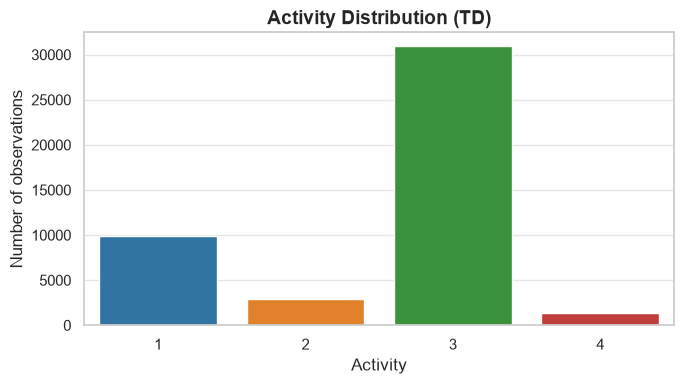

In [129]:
# See the class distribution
print(y_train.value_counts(normalize=True).sort_index().round(3))
plt.figure(figsize=(7, 4))

sns.countplot(x=y_train, palette="tab10" )

plt.title("Activity Distribution (TD)", fontsize=14, fontweight="bold")
plt.xlabel("Activity")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

When looking at the plot, activity 3 have quite a lot of data compared to the rest. Therefore `Stratify` is going to be have to be used. So preserve the proportion of each activity across the training, validation, and test sets. This ensures that all activities are represented fairly in each split.

## Skewed data?
**Why skewness matters** Ch. 2 says that when a feature has a heavy tail, most ML algorithms do not work as well, and should transform it so it is more symmetric (the book uses a **log** transform). We measure skewness with `.skew()`.




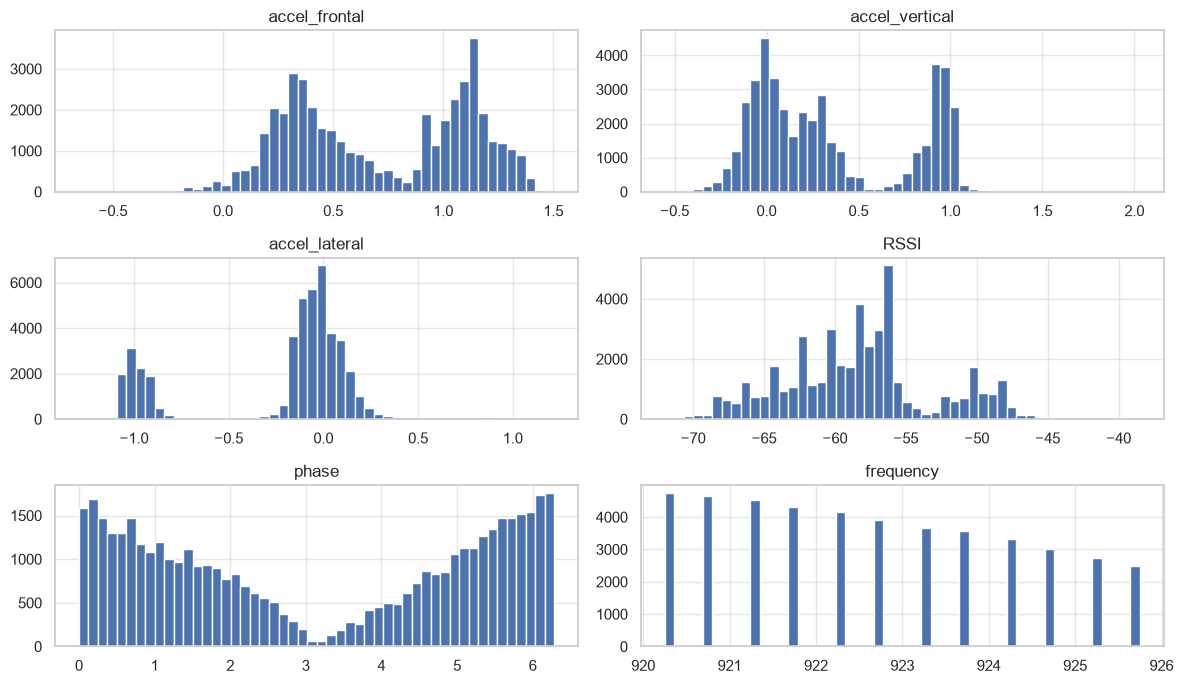

Skewness (0 = symmetric):
accel_frontal    -0.07
accel_vertical    0.48
accel_lateral    -0.77
RSSI              0.24
phase             0.01
frequency         0.23
dtype: float64


In [130]:
# Histograms: shows scale and skewness of each numeric feature (Ch. 2 uses hist() for this) (p. 108, 55)
num_cols = ["accel_frontal", "accel_vertical", "accel_lateral", "RSSI", "phase", "frequency"] # The class is above plus antenna id are taken out here.
X_train[num_cols].hist(bins=50, figsize=(12, 7))
plt.tight_layout()
plt.show()

print("Skewness (0 = symmetric):")
print(X_train[num_cols].skew().round(2))

When looking at the features plotted. The features had very different scales and had different ranges.

The histograms show the shape of each individual feature. They show distributions, concentrated values, long tails, and possible extreme observations.

## Pairwise feature relationships
The pair plot compares features two at at time and colours the observations by class, which makes them easier to see how the features separate.

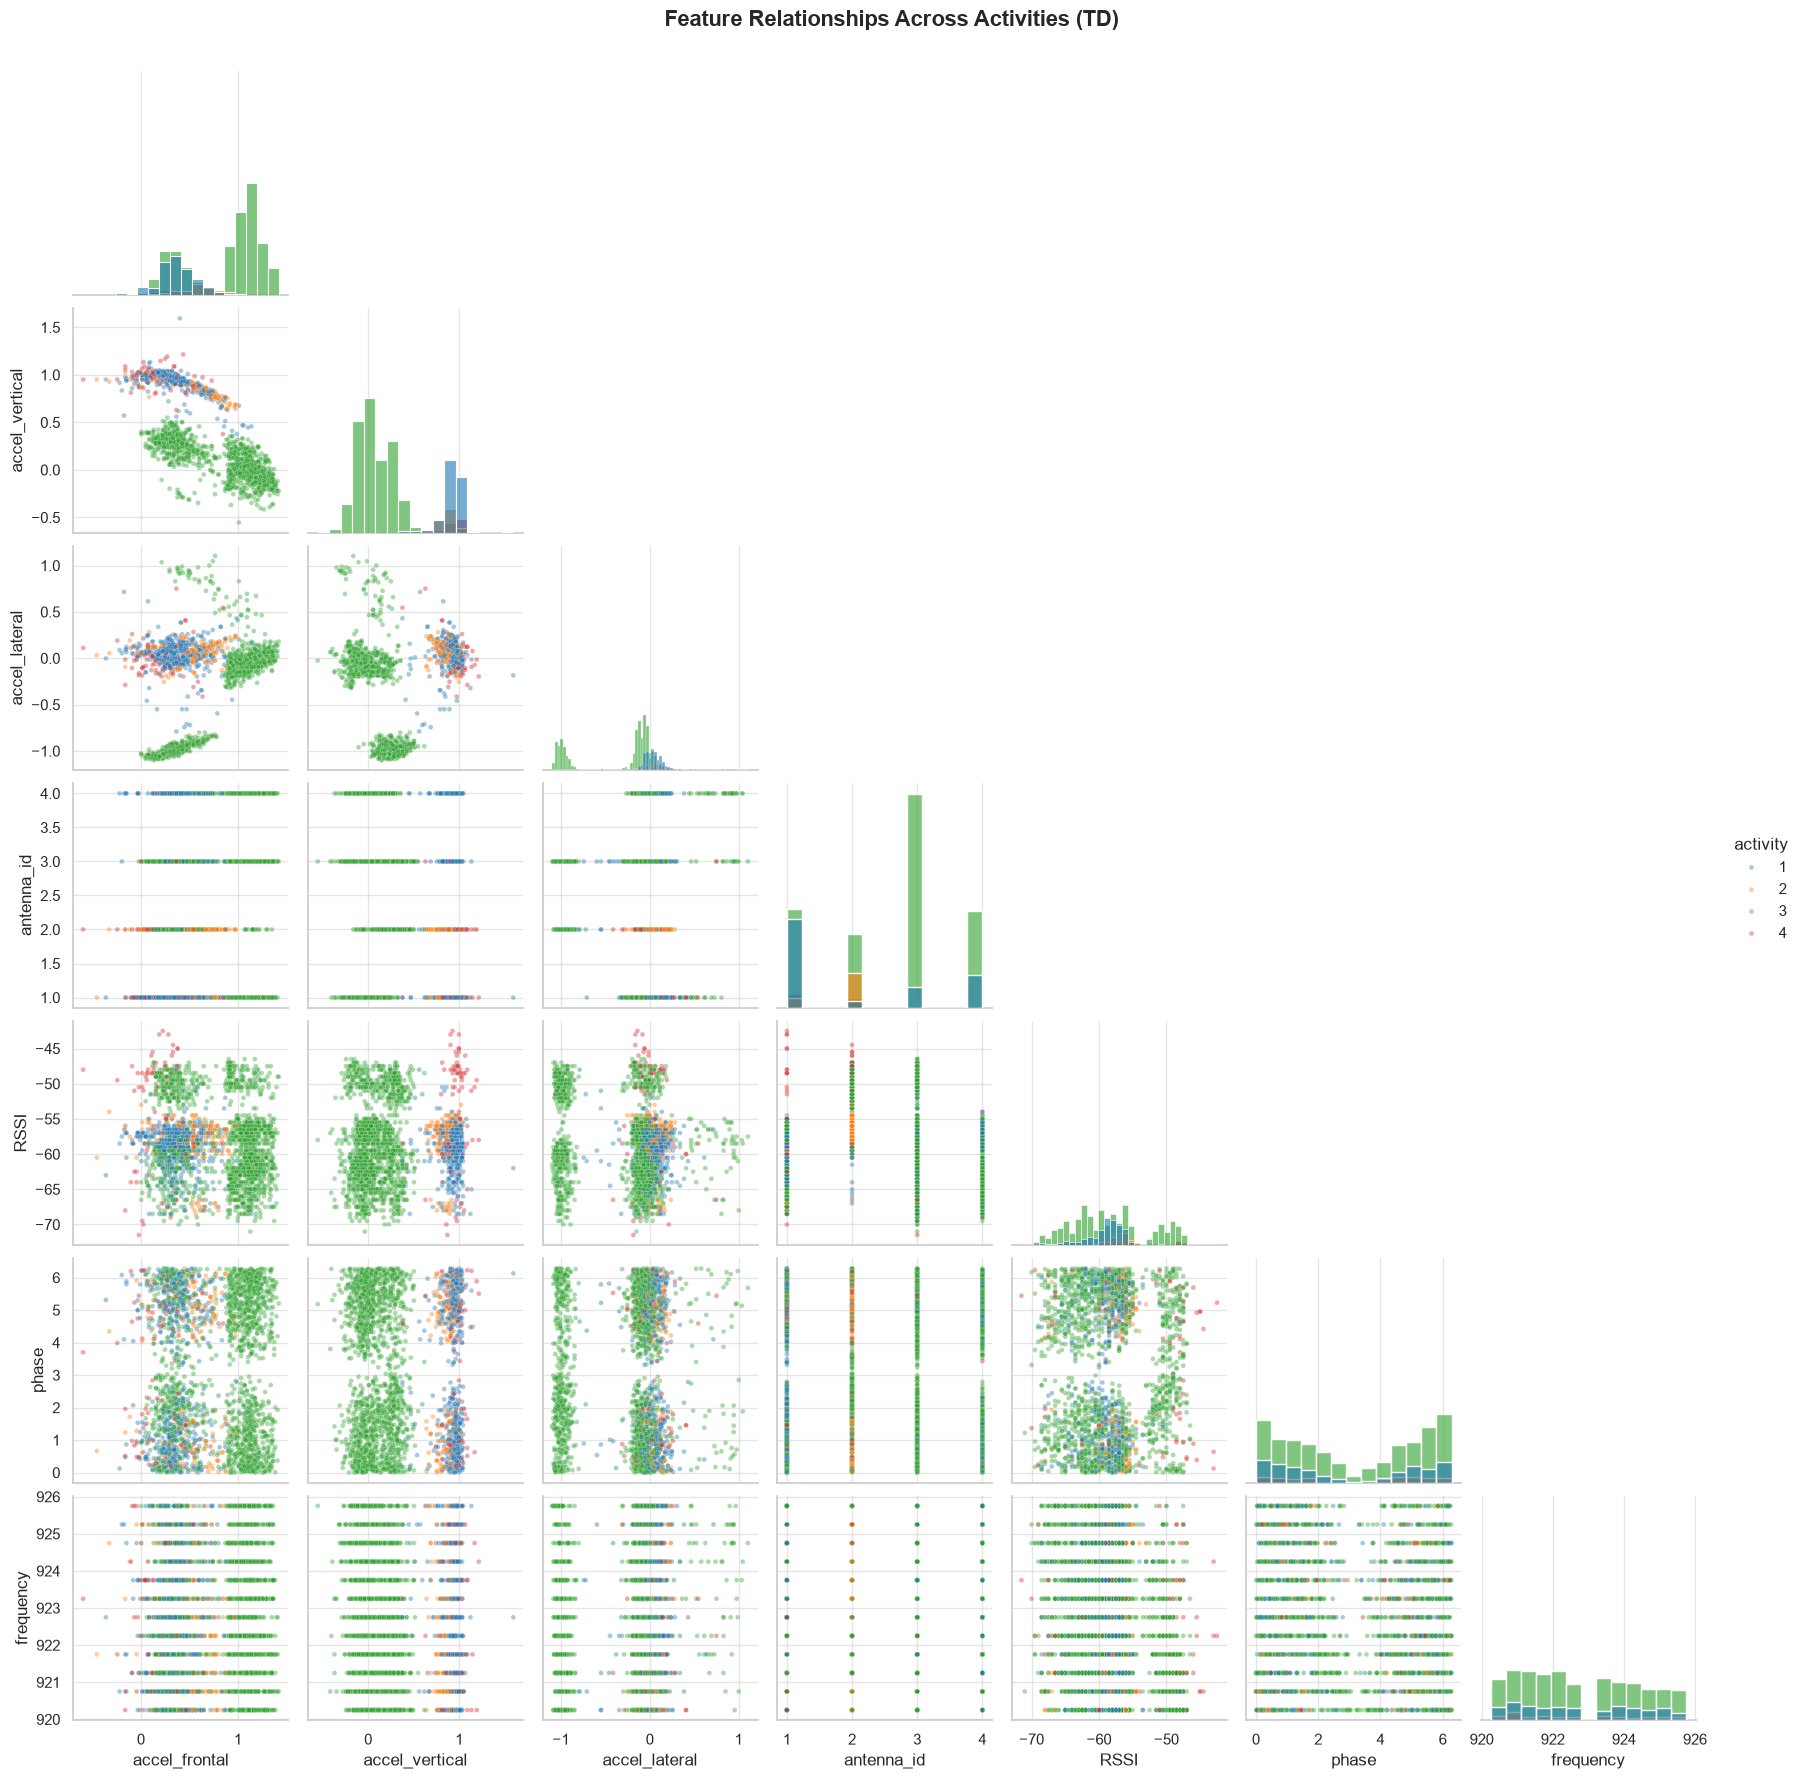

In [131]:
# Prepare data for visualization
plot_data = X_train.copy()
plot_data["activity"] = y_train

# Set visualization style
sns.set_theme(style="whitegrid", context="notebook")

# Create pairplot
g = sns.pairplot(
    plot_data.sample(n=min(2500, len(plot_data)), random_state=42),
    hue="activity",
    palette="tab10",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 12},
    diag_kws={"alpha": 0.6}
)

# Add title
g.figure.suptitle(
    "Feature Relationships Across Activities (TD)",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.show()


## Correlation Matrix

**Why:** Ch. 2 uses the correlation matrix to spot features linked to the target and features that duplicate each other. Lastly, the correlation matrix shows the strength and direction of linear relationships between input features. Strong correlations can indicate overlapping information and maybe corresation

Remember the book's warning: the correlation coefficient only measures **linear** relationships. A feature with ~0 correlation to `activity` can still be very useful in a non-linear model, so we do not drop features based on this plot alone.

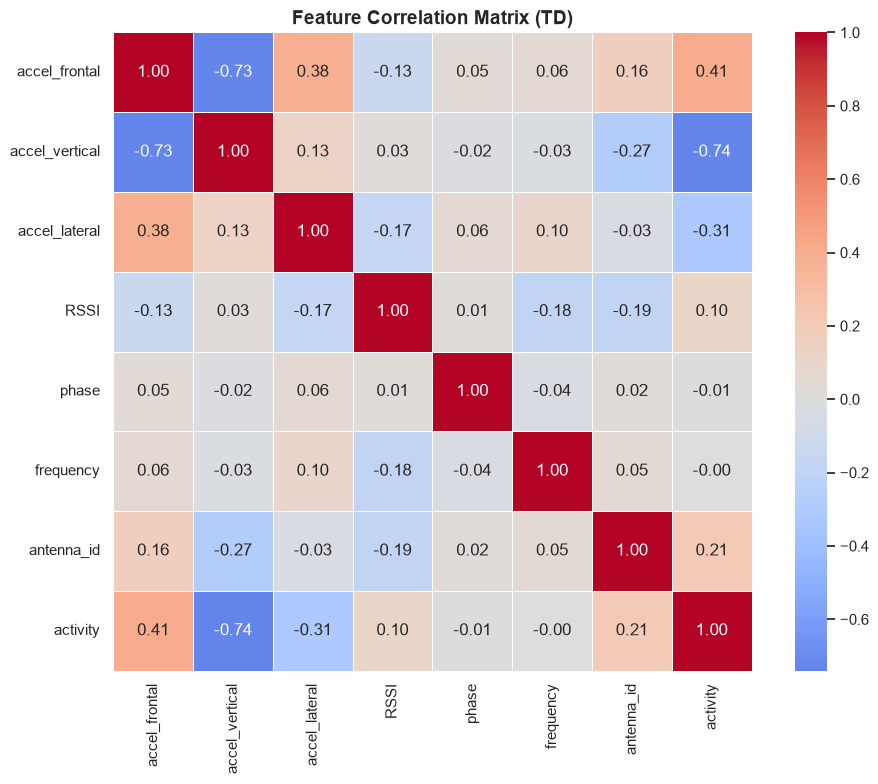

In [132]:
# Correlation matrix (Ch. 2: corr()) - to see which features move together
# Antenna_id and activity are added again.
corr_data = X_train[num_cols + ["antenna_id"]].copy()
corr_data["activity"] = y_train

# Calculate correlation matrix
corr_matrix = corr_data.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Feature Correlation Matrix (TD)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Boxplots - Feature Distribution Across Activities
Boxplots are used to compare the distribution of each numerical featre across the four activities. This helps idenfity the differences in median values, variation and see potential outliers.

*It also gives an indication of which sensor measurements could be useful for distuingusihing between different activities.*

What it shows:
- Median: The line inside each box represents the middle value.
- Interquartile range (IQR): The box shows the middle 50% of observations.
- Whiskers: Show the spread of the data outside the box.
- Outliers: Individual points outside the whiskers indicate unusual values.

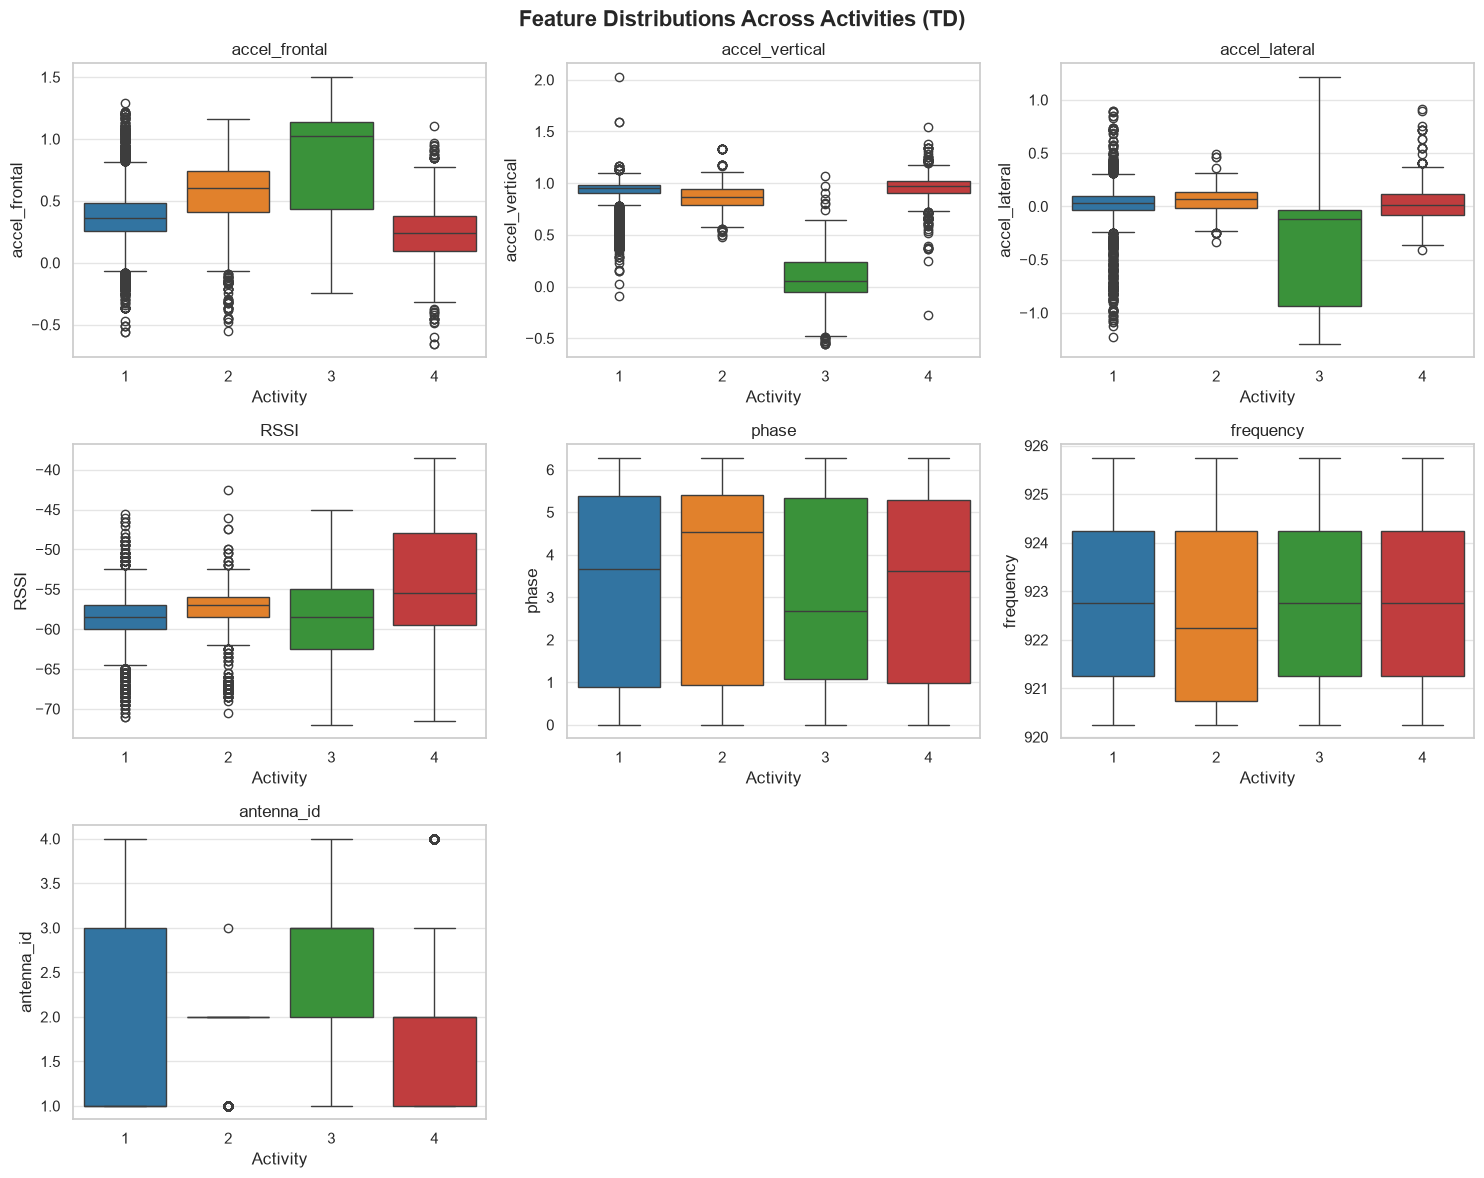

In [133]:
# Which features separate the activities?
plot_data = X_train.copy()
plot_data["activity"] = y_train

plot_cols = num_cols + ["antenna_id"]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, col in zip(axes.ravel(), plot_cols):
    sns.boxplot(
        x="activity",
        y=col,
        data=plot_data,
        palette="tab10",
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("Activity")
    ax.set_ylabel(col)

# Hide unused subplot slots
for ax in axes.ravel()[len(plot_cols):]:
    ax.set_visible(False)

plt.suptitle(
    "Feature Distributions Across Activities (TD)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

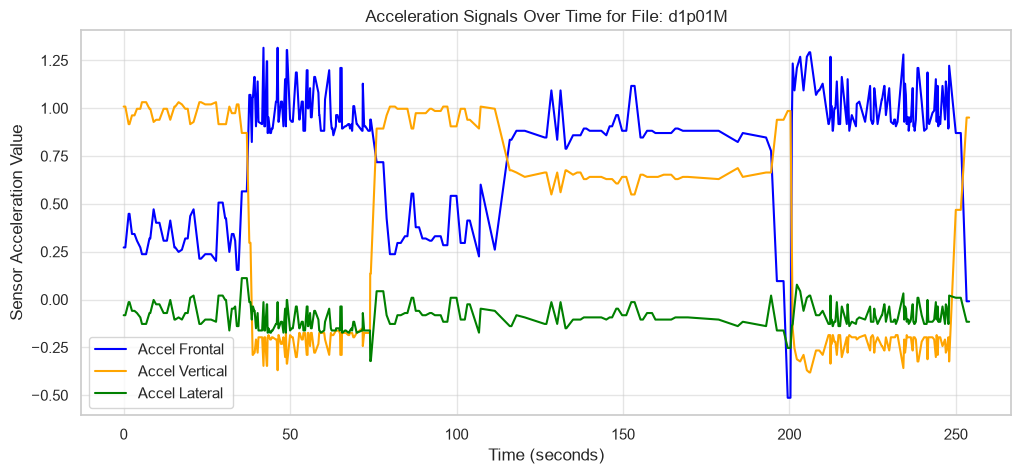

In [134]:
# We filter the data for a single sample file to inspect continuous sensor readings over time - just to see the data and how it moves
sample_file_name = df['source_file'].iloc[0]
subset_df = df[df['source_file'] == sample_file_name].head(1000)

plt.figure(figsize=(12, 5)) # for the plot
plt.plot(subset_df['time'], subset_df['accel_frontal'], label='Accel Frontal', color='blue')
plt.plot(subset_df['time'], subset_df['accel_vertical'], label='Accel Vertical', color='orange')
plt.plot(subset_df['time'], subset_df['accel_lateral'], label='Accel Lateral', color='green')
plt.title(f'Acceleration Signals Over Time for File: {sample_file_name}')
plt.xlabel('Time (seconds)')
plt.ylabel('Sensor Acceleration Value')
plt.legend()
plt.show()

# 4. Preprocessing pipeline
Check the data quality and the structure of it. - We checked earlier that no missing values were counted in **Section 3.**

Duplicate feature rows are counted to identify repeated observations.

`nunique()` reveals features with only one unique value.

The target distribution is printed to see the class imbalance during modeling.

`dtypes` confirms the input columns have have suitabvle numerical datatypes for the scikit-lean estimators. These tell whether to clean or converse insteaf of transformations.

The pipeline includes a median imputer to handle potential missing values. If none exist, it has no effect. Otherwise, it calculates the median using only the training data to prevent data leakage :)

In [122]:
# Check for duplicate feature rows
print("\nDuplicate feature rows:", X_train.duplicated().sum())

# Check for unique values per feature
print("\nUnique values per feature:")
print(X_train.nunique())

# Check the target distribution
print("\nTarget distribution:")
print(y_train.value_counts().sort_index())

# Confirm whether the categorical input features exist
print("\nData types:")
print(X_train.dtypes)



Duplicate feature rows: 13230

Unique values per feature:
accel_frontal      171
accel_vertical     164
accel_lateral      203
antenna_id           4
RSSI                68
phase             3713
frequency           12
subject_folder       2
dtype: int64

Target distribution:
activity
1     9843
2     2947
3    30911
4     1375
Name: count, dtype: int64

Data types:
accel_frontal     float64
accel_vertical    float64
accel_lateral     float64
antenna_id          int64
RSSI              float64
phase             float64
frequency         float64
subject_folder        str
dtype: object

Data types:
accel_frontal     float64
accel_vertical    float64
accel_lateral     float64
antenna_id          int64
RSSI              float64
phase             float64
frequency         float64
subject_folder        str
dtype: object


## Transformations


In [136]:
# Signed log transformation for positive and negative values (pp.79-81)
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))


# Pipeline for skewed numerical features
skewed_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("signed_log", FunctionTransformer(
        signed_log, feature_names_out="one-to-one"
    )),
    ("scale", StandardScaler()),
])

# Pipeline for other numerical features
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Pipeline for categorical features
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Combine the transformations
transformers = [
    ("cat", cat_pipe, ["antenna_id"])
]

if skewed_cols:
    transformers.append(("skewed", skewed_pipe, skewed_cols))

if other_num_cols:
    transformers.append(("num", num_pipe, other_num_cols))

preprocess = ColumnTransformer(transformers)

s

Features after preprocessing: 10

Skewness before preprocessing:
accel_frontal    -0.07
accel_vertical    0.48
accel_lateral    -0.78
RSSI              0.23
phase             0.01
frequency         0.23
dtype: float64

Skewness after preprocessing:
skewed__accel_lateral   -0.63
num__accel_frontal      -0.07
num__accel_vertical      0.48
num__RSSI                0.23
num__phase               0.01
num__frequency           0.23
dtype: float64


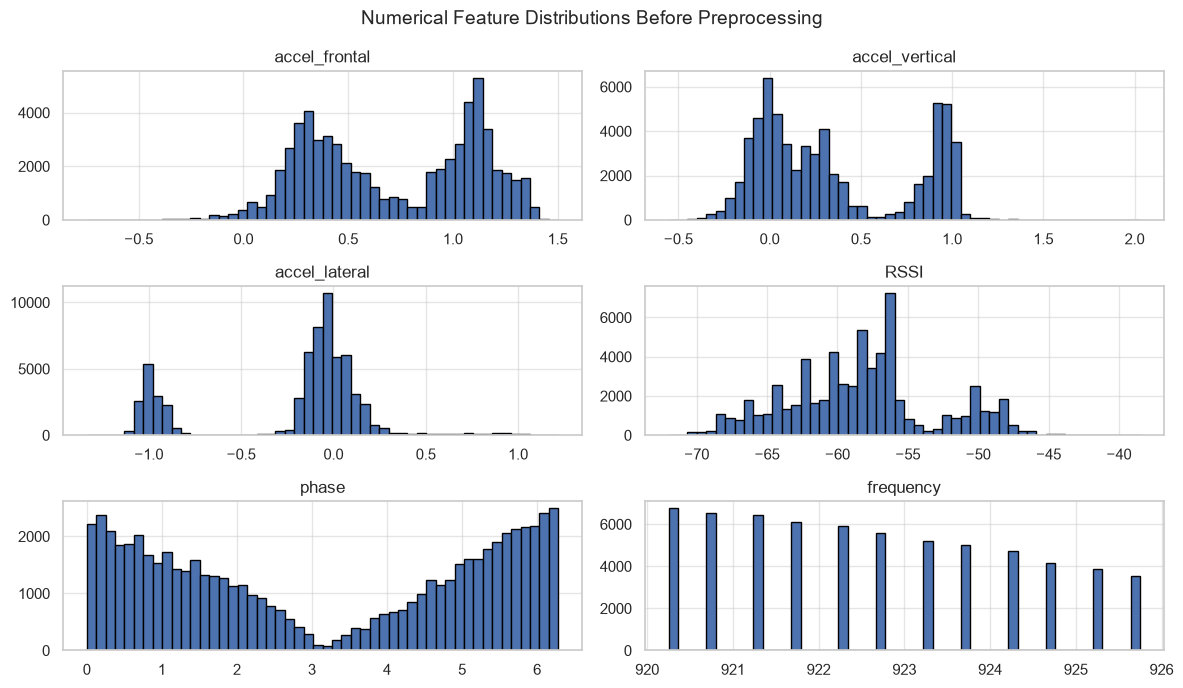

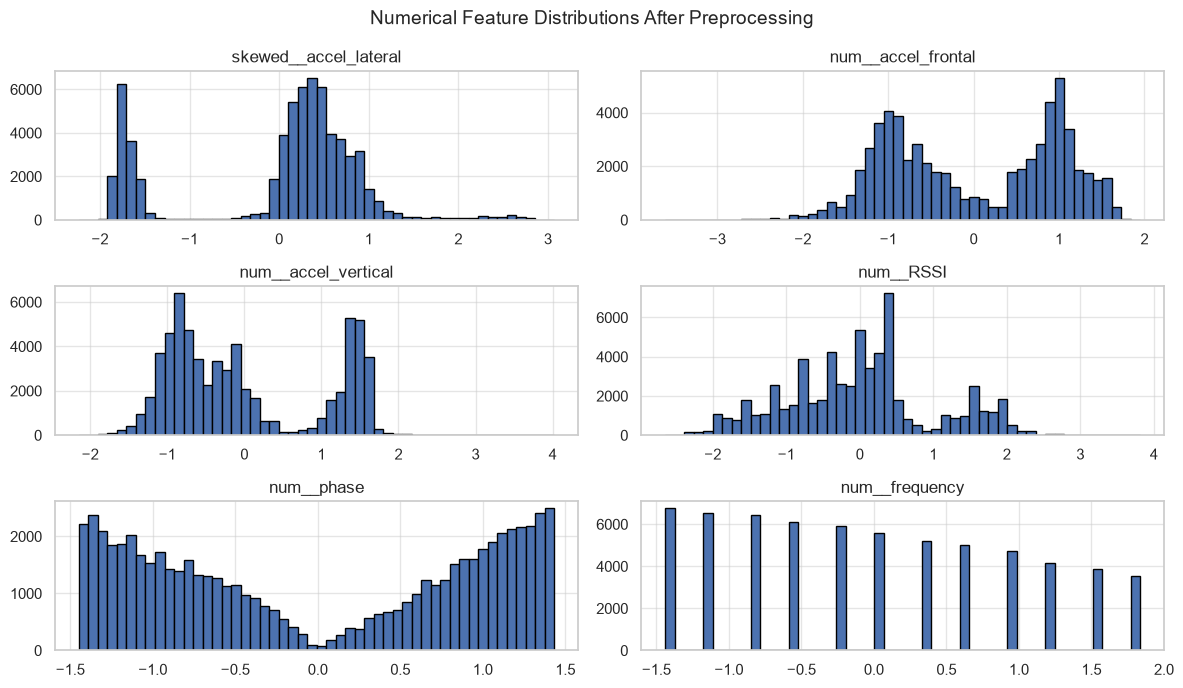

In [143]:
# Fit and transform the development data for inspection
Xt = preprocess.fit_transform(X_traindev)

print("Features after preprocessing:", Xt.shape[1])

# Convert transformed data to a DataFrame
Xt_df = pd.DataFrame(
    Xt.toarray() if hasattr(Xt, "toarray") else Xt,
    columns=preprocess.get_feature_names_out(),
    index=X_traindev.index
)

# Select numerical features before and after preprocessing
before = X_traindev[num_cols]
after = Xt_df.filter(regex=r"^(skewed|num)__")

# Compare skewness
print("\nSkewness before preprocessing:")
print(before.skew().round(2))

print("\nSkewness after preprocessing:")
print(after.skew().round(2))

# Plot distributions before  - also shown earlier up.
before.hist(
    bins=50,
    figsize=(12, 7),
    edgecolor="black"
)
plt.suptitle("Numerical Feature Distributions Before Preprocessing",
             fontsize=14)
plt.tight_layout()
plt.show()

# Plot distributions after preprocessing
after.hist(
    bins=50,
    figsize=(12, 7),
    edgecolor="black"
)
plt.suptitle("Numerical Feature Distributions After Preprocessing",
             fontsize=14)
plt.tight_layout()
plt.show()

A look at the data shows:
- accel_frontal: Remained unchanged at -0.07, maintaining an approximately symetric distribution.
- accel_vertical: Remained unchanged at 0.48, showing an slight positive skew.
- accel_lateral: Improved slightly from -0.78 to -0.63, which indicates a negative skew that was a bit reduced
- RSSI: Remained unchanged at 0.23, ish symmetric distribution.
- phase: Remained unchanged at 0.01, an almost perfectly symmetric distribution.
- frequency: Remained unchanged at 0.23, ish symmetric distribution.

# 5. Baseline - Dummy Classifier
A `DummyClassifier` that *always* predicts the most frequent class tells us the "do nothging" accuracy that every real model must beat.

We use **accuracy** and **macro-F1** (the average F1 over classes, which treats each class equally, so it is not fooled by class imbalance; F1 is from Ch. 3 p.111).

https://www.geeksforgeeks.org/machine-learning/ml-dummy-classifiers-using-sklearn/

In [259]:
# Evaluation metrics
scoring = {
    "acc": "accuracy",
    "f1_macro": "f1_macro"
}

# Store results
results = {}

def cv_report(name, estimator, X=X_train, y=y_train):
    scores = cross_validate(
        estimator,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results[name] = {
        "Accuracy": scores["test_acc"].mean(),
        "Macro-F1": scores["test_f1_macro"].mean()
    }

    print(
        f"{name}: "
        f"Accuracy = {results[name]['Accuracy']:.4f}, "
        f"Macro-F1 = {results[name]['Macro-F1']:.4f}"
    )

# Baseline model
dummy = Pipeline([
    ("prep", preprocess),
    ("clf", DummyClassifier(strategy="most_frequent")) # there are: strategies = ['most_frequent', 'stratified', 'uniform', 'constant']
])

cv_report("Baseline (most frequent class)", dummy)

Baseline (most frequent class): Accuracy = 0.6858, Macro-F1 = 0.2034


# 6. Define model pipelines
Four different classifiers are compared as they represent different learning ways of decicion boundaries.
- Model 1. Logistic Regresstion (chap 4.)
    - a linear baseline
        - `multi_class` parameter is deprecated, and multinominal is used automatically for compatible solvers when more than two classes
- Model 2: Decicion Trees
    - it learns interpretable feature thresholds
- Model 3: Support Vector Machine (SVM) (chap. 5)
    - can form linear or nonlinear boundaries
- Model 4: Random Forest (chap. 6-7)
    - multiple trees to model complex patterns


In [ ]:

# Imports
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, PowerTransformer, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV

# Define models
models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess),
        ("power", "passthrough"),
        ("poly", "passthrough"),
        ("reduce", "passthrough"),
        ("model", LogisticRegression(
            solver="lbfgs",
            class_weight="balanced",
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": Pipeline([
        ("prep", preprocess),
        ("model", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("prep", preprocess),
        ("model", RandomForestClassifier(
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "SVM": Pipeline([
        ("prep", preprocess),
        ("power", "passthrough"),
        ("model", SVC(
            class_weight="balanced"
        ))
    ])
}

# Define hyperparameter grids
param_grids = {

    "Logistic Regression": {
        "power": [
            "passthrough",
            PowerTransformer(method="yeo-johnson", standardize=False)
        ],
        "poly": [
            "passthrough",
            PolynomialFeatures(degree=2, include_bias=False)
        ],
        "reduce": [
            "passthrough",
            PCA(n_components=0.95),
            PCA(n_components=0.99)
        ],
        "model__C": [0.01, 0.1, 1, 10, 100]
    },

    "Decision Tree": {
        "model__max_depth": [None, 5, 10, 20],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 5, 10]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": ["sqrt", 0.5]
    },

    "SVM": [
        {
            "power": [
                "passthrough",
                PowerTransformer(method="yeo-johnson", standardize=False)
            ],
            "model__kernel": ["rbf"],
            "model__C": [0.1, 1, 10, 100],
            "model__gamma": ["scale", 0.01, 0.1]
        },
        {
            "power": [
                "passthrough",
                PowerTransformer(method="yeo-johnson", standardize=False)
            ],
            "model__kernel": ["poly"],
            "model__C": [0.1, 1, 10],
            "model__gamma": ["scale", 0.1],
            "model__degree": [2, 3]
        }
    ]
}

# 6.1 - Model 1. Multinominal Logistic Regresstion (chap 4. pp. 164-173)
A linear model:
- computes the weighted sum of the features and turns them into class probabilities with the softmax function.
- It can only draw linear bondaries, so the simplest yipie
- Multinomial Logistic Regression as the target variable contains four activity classes.
- Unlike binary Logistic Regression, which distinguishes between two classes, multinomial Logistic Regression can classify observations into multiple categories.

Used the `lbfgs` solver and max number of iterations to 3000. The model is trained on the dataset and evaluated on the validation dataset using accuracy, precicion, recall and macro f1.

https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/

In [227]:
# Train it!
logreg = models["Logistic Regression"] # select the model

logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Macro-F1:", round(f1_score(y_val, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))


Accuracy: 0.9493
Macro-F1: 0.8087

Classification Report:
              precision    recall  f1-score   support

           1       0.93      0.87      0.90      3281
           2       0.79      0.91      0.85       982
           3       1.00      1.00      1.00     10305
           4       0.47      0.52      0.49       458

    accuracy                           0.95     15026
   macro avg       0.80      0.82      0.81     15026
weighted avg       0.95      0.95      0.95     15026



A confusion matrix is also used to see where misclassifications occur.

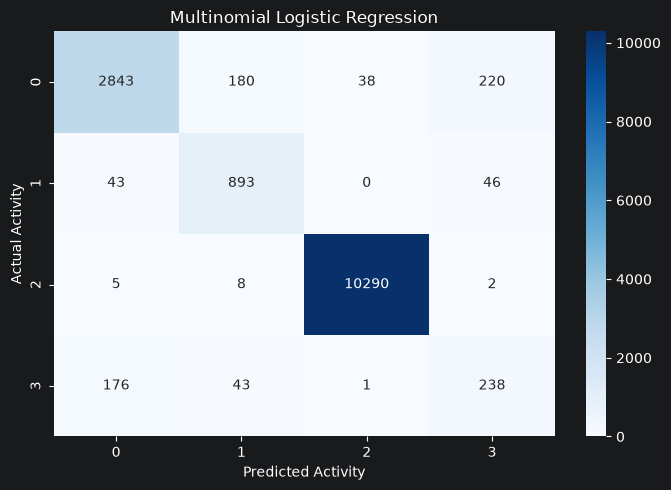

In [228]:
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Multinomial Logistic Regression")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.tight_layout()
plt.show()

# 6.2 - Model 2: Decision Trees
A Decision tree:
- splits the data with a series of yes/no question on single features.
- A single big (deep) tree overfits
- A random forest trains many trees on random bootstrap samples with random subsets of features and averages theirt votes which reduces variance (bagging).
- The trees need no feature scaling, handle non-linear relationshios and interations, and give feature importances.
- supervised learning algortihm good for classification and regression tasks.

https://www.geeksforgeeks.org/machine-learning/decision-tree-introduction-example/

In [229]:
# Train it!
logreg = models["Decision Tree"] # select the model

logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Macro-F1:", round(f1_score(y_val, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))


Accuracy: 0.9834
Macro-F1: 0.9336

Classification Report:
              precision    recall  f1-score   support

           1       0.97      0.97      0.97      3281
           2       0.95      0.96      0.95       982
           3       1.00      1.00      1.00     10305
           4       0.83      0.80      0.82       458

    accuracy                           0.98     15026
   macro avg       0.94      0.93      0.93     15026
weighted avg       0.98      0.98      0.98     15026



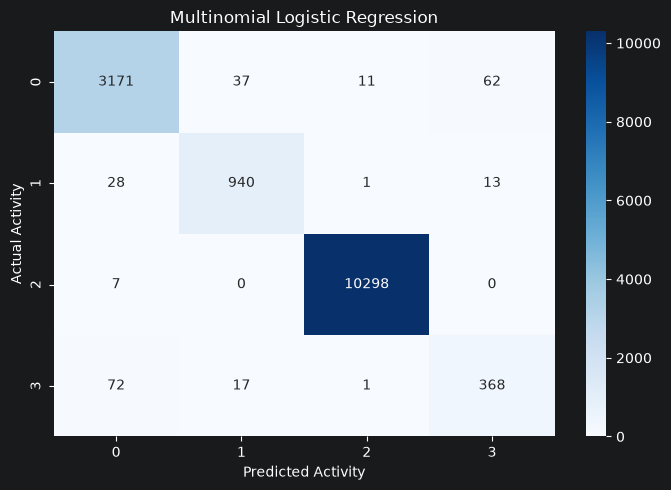

In [230]:
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Multinomial Logistic Regression")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.tight_layout()
plt.show()

# 6.3 - Model 3: Random Forest (pp. 90, 211, 220-222)
A ML algortihm that uses many decision trees to make better predictions. Each tree takes different data, and their results are combined, by voting for classification or averageing regression. They are trained via the *bagging method (or sometimes pasting)*. `RandomForestClassifier` is optimized for desicion trees.

https://www.geeksforgeeks.org/machine-learning/random-forest-algorithm-in-machine-learning/

In [231]:
# Train it!
logreg = models["Random Forest"] # select the model

logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Macro-F1:", round(f1_score(y_val, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))


Accuracy: 0.9873
Macro-F1: 0.9471

Classification Report:
              precision    recall  f1-score   support

           1       0.96      0.99      0.97      3281
           2       0.96      0.97      0.97       982
           3       1.00      1.00      1.00     10305
           4       0.96      0.76      0.85       458

    accuracy                           0.99     15026
   macro avg       0.97      0.93      0.95     15026
weighted avg       0.99      0.99      0.99     15026



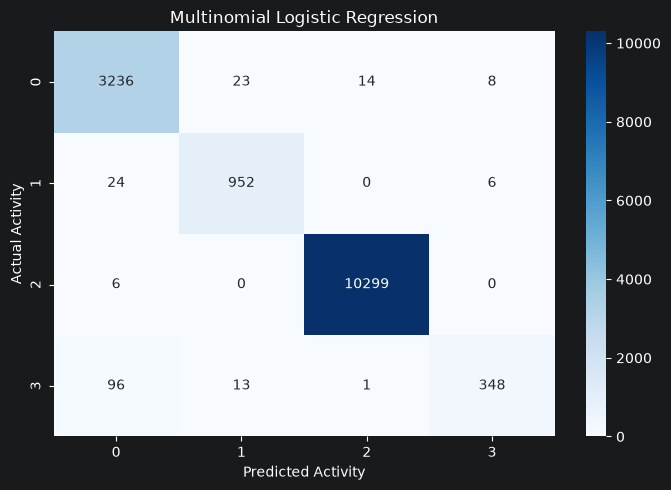

In [232]:
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Multinomial Logistic Regression")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.tight_layout()
plt.show()

# 6.4 - Model 4: Support Vector Machine (SVM) (chap. 5)
A versatile suppervised ML algorithm used to classification and regression tasks. it tries to find the best boundary *(hyperplane)* that separates the different classes in the data.

https://www.geeksforgeeks.org/machine-learning/support-vector-machine-algorithm/

In [219]:
# Train it!
logreg = models["SVM"] # select the model

logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Macro-F1:", round(f1_score(y_val, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

Accuracy: 0.9642
Macro-F1: 0.8646

Classification Report:
              precision    recall  f1-score   support

           1       0.95      0.90      0.92      3281
           2       0.84      0.96      0.90       982
           3       1.00      1.00      1.00     10305
           4       0.64      0.64      0.64       458

    accuracy                           0.96     15026
   macro avg       0.86      0.87      0.86     15026
weighted avg       0.97      0.96      0.96     15026



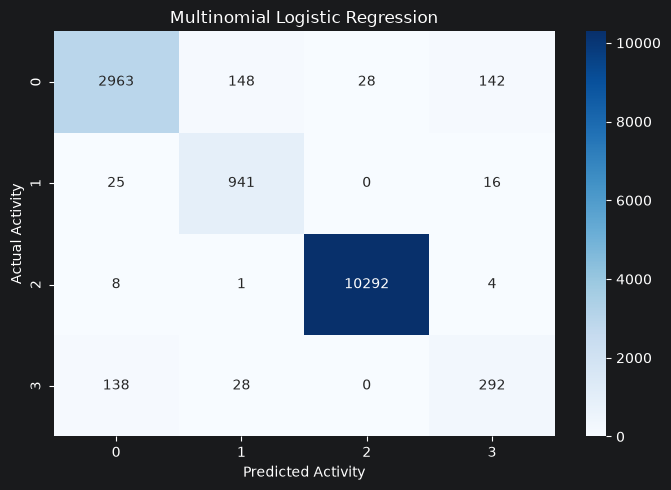

In [220]:
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Multinomial Logistic Regression")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.tight_layout()
plt.show()

# 7. Tune the models with cross-validation
`GridSearchCV` tests the predefined hyperparameters cobinations from **Model and Hyperparamater definition (6)** on each model. Each candidate is evaluated using the five stratified cross-validation splits, preserving the class proportions across the folds.

The models are evaluated using the `scoring=f1_macro` to account for the imbalanced activity classes. The macro-F1 is the selection criterion.

This is suitalbe for imbalanced multiclass data because it treats all four classes equally. The best parameters and models are then stored for comparison.


`grid.fit(X_train, y_train)` performs the tuning using only the training data. Preprocessing is fitted within each fold (5 folds) to prevent data leakage. The best model is refitted `refit=Macro-F1` on the full training set. It tells it which metric to use when selecting the best hyperparameters and refitting the final model. `return_train_score=True` retains while training scores and be compared with cross-validation scores to help identify possible overfitting. `error_score="raise"` makes an invalid stop with an error, instad of a failed score. `n_jobs=1` controls how many CPU cores are used during GridSearchCV.

In [258]:
# Tune all models using GridSearchCV
grid_results = {}
best_models = {}
grid_searches = {}

for name, model in models.items():

    print(f"\n~~~~~~~~~ Tuning {name} ~~~~~~~~~")

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring={"Accuracy": "accuracy", "Macro-F1": "f1_macro"},
        refit="Macro-F1",
        cv=cv, # StratifiedShuffleSplit 5 splits
        n_jobs=-1,
        return_train_score=True,
        error_score="raise",
    )

    grid.fit(X_train, y_train)

    # store the fitted GSCV object
    grid_searches[name] = grid

    # store the best fitted model
    best_models[name] = grid.best_estimator_

    grid_results[name] = {
        "Best Parameters": grid.best_params_,
        "Best CV Macro-F1": grid.best_score_,
    }

    print("Best parameters:", grid.best_params_)
    print("Best CV Macro-F1:", round(grid.best_score_, 4))


~~~~~~~~~ Tuning Logistic Regression ~~~~~~~~~
Best parameters: {'model__C': 1, 'poly': PolynomialFeatures(include_bias=False), 'power': 'passthrough', 'reduce': 'passthrough'}
Best CV Macro-F1: 0.8511

~~~~~~~~~ Tuning Decision Tree ~~~~~~~~~
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Best CV Macro-F1: 0.9282

~~~~~~~~~ Tuning Random Forest ~~~~~~~~~
Best parameters: {'model__max_depth': 20, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best CV Macro-F1: 0.9469

~~~~~~~~~ Tuning SVM ~~~~~~~~~
Best parameters: {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf', 'power': 'passthrough'}
Best CV Macro-F1: 0.8987


# 8. PCA - Principal Component Analysis
This part explores how many components are needed to retain 95% of the variance :)

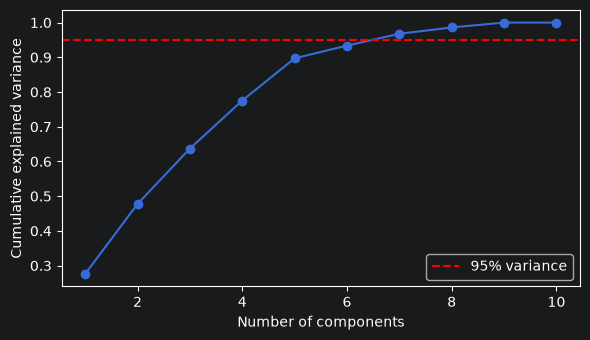

Components needed for 95% variance: 7 of 10


In [262]:
# Fit preprocessing on the development data
Xt = preprocess.fit_transform(X_train)

# PCA requires dense input
if hasattr(Xt, "toarray"):
    Xt = Xt.toarray()

pca_full = PCA().fit(Xt)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(cumvar) + 1), cumvar, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.legend()
plt.tight_layout()
plt.show()

n_components = np.argmax(cumvar >= 0.95) + 1
print(f"Components needed for 95% variance: {n_components} of {Xt.shape[1]}")

The L1 feature selection. This identifies which transformed features can be removed by an L1-regularised linear model.

In [263]:
names = preprocess.get_feature_names_out()

for C in [0.001, 0.01, 0.1]:
    selector = SelectFromModel(
        LinearSVC(penalty="l1", dual=False, C=C, max_iter=5000)
    )
    selector.fit(Xt, y_train)

    selected = names[selector.get_support()]

    print(f"\nC={C}: keeps {len(selected)} of {len(names)} features")
    print(list(selected))


C=0.001: keeps 7 of 10 features
['cat__antenna_id_2', 'cat__antenna_id_4', 'skewed__accel_lateral', 'num__accel_frontal', 'num__accel_vertical', 'num__RSSI', 'num__frequency']

C=0.01: keeps 10 of 10 features
['cat__antenna_id_1', 'cat__antenna_id_2', 'cat__antenna_id_3', 'cat__antenna_id_4', 'skewed__accel_lateral', 'num__accel_frontal', 'num__accel_vertical', 'num__RSSI', 'num__phase', 'num__frequency']

C=0.1: keeps 10 of 10 features
['cat__antenna_id_1', 'cat__antenna_id_2', 'cat__antenna_id_3', 'cat__antenna_id_4', 'skewed__accel_lateral', 'num__accel_frontal', 'num__accel_vertical', 'num__RSSI', 'num__phase', 'num__frequency']


Then try it with a random forest as in section 7. I used the fitted model :)

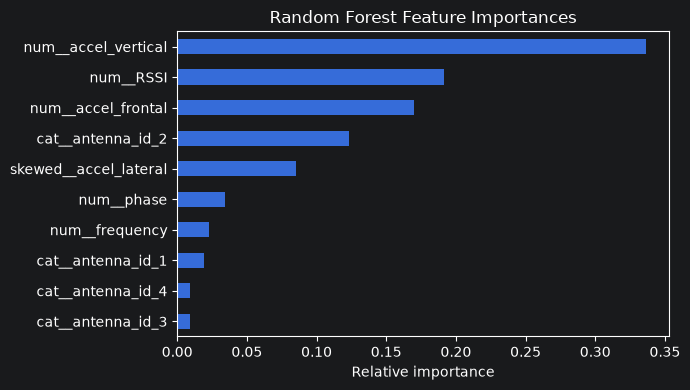

Random Forest + PCA: Accuracy = 0.9809, Macro-F1 = 0.9305


In [289]:
# Create a copy of the best Random Forest model
rf_copy = best_models["Random Forest"]

names = rf_copy.named_steps["prep"].get_feature_names_out()

importance = pd.Series(
    rf_copy.named_steps["model"].feature_importances_,
    index=names
).sort_values()

importance.plot(kind="barh", figsize=(7, 4))
plt.title("Random Forest Feature Importances")
plt.xlabel("Relative importance")
plt.tight_layout()
plt.show()

# Evaluate Random Forest with PCA
cv_report("Random Forest + PCA", rf_pca)

# 9. - Compare cross-validation results
The best setup from each model is made into a table. The `best_params_` is the cobination from `GridSearchCV`. `best_score_` is the highest average cross-validation score achieved by the best hyperparameter cobination. As set `refit="Macro-F1`, it represents the highest average validation score across the 5 cross-validation splits.

In [295]:
# Compare baseline, PCA and tuned models
summary = pd.DataFrame([
    {
        "Model": name,
        "CV Accuracy": v["Accuracy"],
        "CV Macro-F1": v["Macro-F1"]
    }
    for name, v in results.items()
])

for name, grid in grid_searches.items():
    summary.loc[len(summary)] = {
        "Model": name,
        "CV Accuracy": grid.cv_results_["mean_test_Accuracy"][grid.best_index_],
        "CV Macro-F1": grid.best_score_
    }

summary = summary.sort_values(
    by="CV Macro-F1", ascending=False
).reset_index(drop=True)

display(summary.round(4))

,Model,CV Accuracy,CV Macro-F1
0,Random Forest,0.9868,0.9469
1,Random Forest + PCA,0.9809,0.9305
2,Decision Tree,0.9810,0.9282
3,SVM,0.9730,0.8987
4,Logistic Regression,0.9586,0.8511
5,Baseline (most frequent class),0.6858,0.2034


# 10. Inspect Precicion-Recall
One-vs-rest (OvR) Precision-Recall evaluates multi-class classification by treating each class as the positive class ("one") and grouping all other classes together as the negative class ("rest"). The Solid lines represent precision and recall, while the colour coded dashed lines indicate the class-specific baselines. The curves closer to the top-right corner indicate a better classification performance.

https://www.geeksforgeeks.org/machine-learning/one-vs-rest-strategy-for-multi-class-classification/


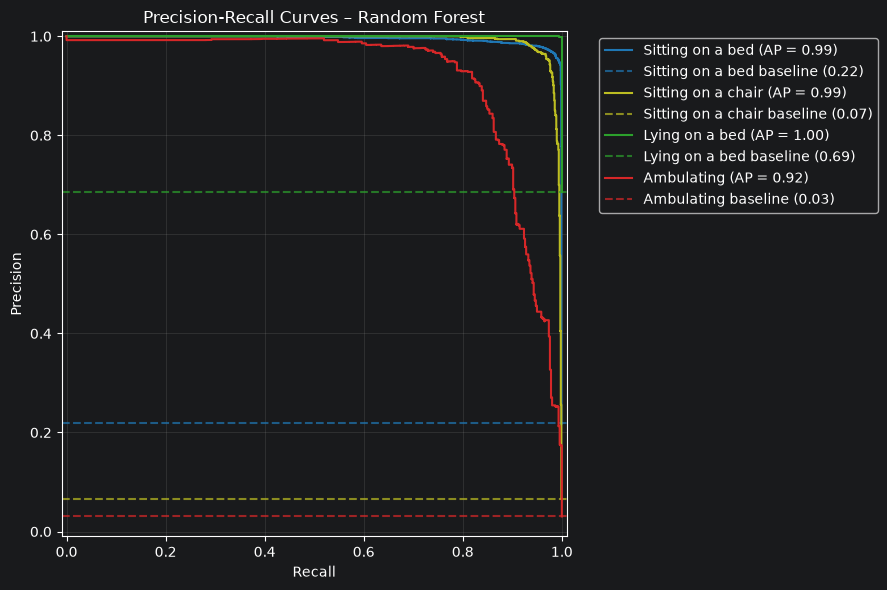

In [304]:
activity_names = {
    1: "Sitting on a bed",
    2: "Sitting on a chair",
    3: "Lying on a bed",
    4: "Ambulating"
}

colors = [
    plt.cm.tab10(0),  # Blue
    plt.cm.tab10(8),  # Yellow
    plt.cm.tab10(2),  # Green
    plt.cm.tab10(3)   # Red
]

fig, ax = plt.subplots(figsize=(8, 6))

for i, activity in enumerate(classes):
    name = activity_names.get(activity, str(activity))

    PrecisionRecallDisplay.from_predictions(
        y_val_binary[:, i],
        y_scores[:, i],
        name=name,
        ax=ax,
        color=colors[i],
        plot_chance_level=False
    )

    baseline = y_val_binary[:, i].mean()
    ax.axhline(
        y=baseline,
        color=colors[i],
        linestyle="--",
        alpha=0.7,
        label=f"{name} baseline ({baseline:.2f})"
    )

ax.set_title(f"Precision-Recall Curves – {best_name}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 11. Choosing the best model and test it!

In [305]:
for name, values in results.items():
    print(name, type(values), values)

Baseline (most frequent class) <class 'dict'> {'Accuracy': np.float64(0.6857808340727596), 'Macro-F1': np.float64(0.20340153957497203)}
Random Forest + PCA <class 'dict'> {'Accuracy': np.float64(0.9809228039041704), 'Macro-F1': np.float64(0.9305130754207696)}


In [306]:
# Compare baseline, PCA and tuned models
summary = pd.DataFrame([
    {
        "Model": name,
        "CV Accuracy": v["Accuracy"],
        "CV Macro-F1": v["Macro-F1"]
    }
    for name, v in results.items()
])

for name, grid in grid_searches.items():
    summary.loc[len(summary)] = {
        "Model": name,
        "CV Accuracy": grid.cv_results_["mean_test_Accuracy"][grid.best_index_],
        "CV Macro-F1": grid.best_score_
    }

summary = summary.sort_values(
    by="CV Macro-F1", ascending=False
).reset_index(drop=True)

display(summary.round(4))

,Model,CV Accuracy,CV Macro-F1
0,Random Forest,0.9868,0.9469
1,Random Forest + PCA,0.9809,0.9305
2,Decision Tree,0.9810,0.9282
3,SVM,0.9730,0.8987
4,Logistic Regression,0.9586,0.8511
5,Baseline (most frequent class),0.6858,0.2034


The f1 macro score is an evaluation metric for multi-class or multi-label classification that calculates the F1 score for each class independently and takes their unweighted arithmetic mean. Every class counts equally, regardless of how many samples it has. From `sklearn.metrics import f1_score` `macro_f1 = f1_score(y_true, y_pred, average="macro")`

In [291]:
# Select the best tuned model
best_name = max(
    grid_searches,
    key=lambda name: grid_searches[name].best_score_
)

final_model = best_models[best_name]

print("Best model:", best_name)

# Evaluate once on the untouched test set
y_pred = final_model.predict(X_test)

print("\nTest Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Test Macro-F1:",
      round(f1_score(y_test, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Best model: Random Forest

Test Accuracy: 0.9859
Test Macro-F1: 0.9423

Classification Report:
              precision    recall  f1-score   support

           1       0.96      0.99      0.97      3282
           2       0.96      0.96      0.96       982
           3       1.00      1.00      1.00     10304
           4       0.97      0.74      0.84       458

    accuracy                           0.99     15026
   macro avg       0.97      0.92      0.94     15026
weighted avg       0.99      0.99      0.99     15026



For a final round off, a confusoion matrix is created. The confusion matrix shows the actual counts os true classifications, false classifications, missed classifications and correctly classified classifications. False negatives mean missing an activity, while false positives mean incorrectly predicting an activity. Both are important when evaluating the models performance.

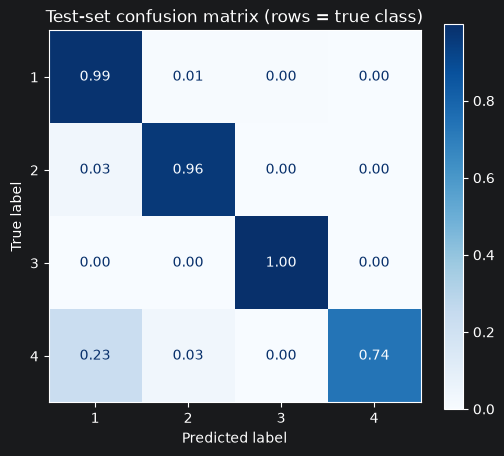

In [292]:
fig, ax = plt.subplots(figsize=(6, 5)) # (pp. 108-111)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", cmap="Blues", ax=ax, values_format=".2f")
ax.set_title("Test-set confusion matrix (rows = true class)")
plt.show()

In [288]:
import random

# A fun little thing :)

# Select a random test sample
random_test_sample = random.randrange(len(X_test))

sample = X_test.iloc[[random_test_sample]]
actual_activity = y_test.iloc[random_test_sample]

# Predict the activity from the best FINAL model
predicted_activity = final_model.predict(sample)[0]

print(f"Predicted activity: {predicted_activity}")
print(f"Actual activity: {actual_activity}")

Predicted activity: 3
Actual activity: 3
